# Experiment 03: Tree size

Card: [exp03_tree_size.md](../../experiments/exp03_tree_size.md)


In [1]:
import os
import sys
from time import strftime

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, MLFLOW_URI
from ashrae.tuning import make_folds, run_trial

SMOKE = os.environ.get("SMOKE") == "1"
LEARNING_RATE = 0.1
if SMOKE:
    EXPERIMENT = "ashrae-baseline-tree_size-smoke"
    TRAIN = True
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    LEAVES = [7, 15]
    MAX_TREES, PATIENCE, CURVE_EVERY = 60, 10, 10
    FIGURE = None
else:
    EXPERIMENT = "ashrae-baseline-tree_size"
    TRAIN = False  # Stage A already ran before the split; True retrains it under a new session
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000  # exp02: more rows don't help
    LEAVES = [31, 63, 127, 255]
    MAX_TREES, PATIENCE, CURVE_EVERY = (
        5000,
        200,
        10,
    )  # every 10th tree of each validation curve goes to MLflow
    FIGURE = "../../figures/exp03_tree_size.png"
SESSION = strftime("%Y-%m-%d %H:%M:%S") if TRAIN else "2026-10-11 12:25:43"

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = mlflow.MlflowClient()

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Trials


In [2]:
if TRAIN:
    folds = make_folds({f: FOLDS[f] for f in FOLD_NAMES}, N_TRAIN, N_VAL)
    for leaves in LEAVES:
        run_trial(
            f"{leaves} leaves",
            {"num_leaves": leaves},
            folds,
            learning_rate=LEARNING_RATE,
            max_trees=MAX_TREES,
            patience=PATIENCE,
            curve_every=CURVE_EVERY,
            logged={"n_train": N_TRAIN, "n_val": N_VAL},
            tags={
                "session": SESSION,
                "stage": "A",
                "model": "lgbm_building",
                "notebook": "exp03_tree_size",
            },
        )

## Results


tags.fold,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average
"RMSLE, all rows",,,,,
31,1.4077,1.2042,1.0319,1.0947,1.1846
63,1.4065,1.2031,1.0463,1.0958,1.1879
127,1.4038,1.2002,1.0274,1.0927,1.1810
255,1.4032,1.2012,1.0217,1.0928,1.1797


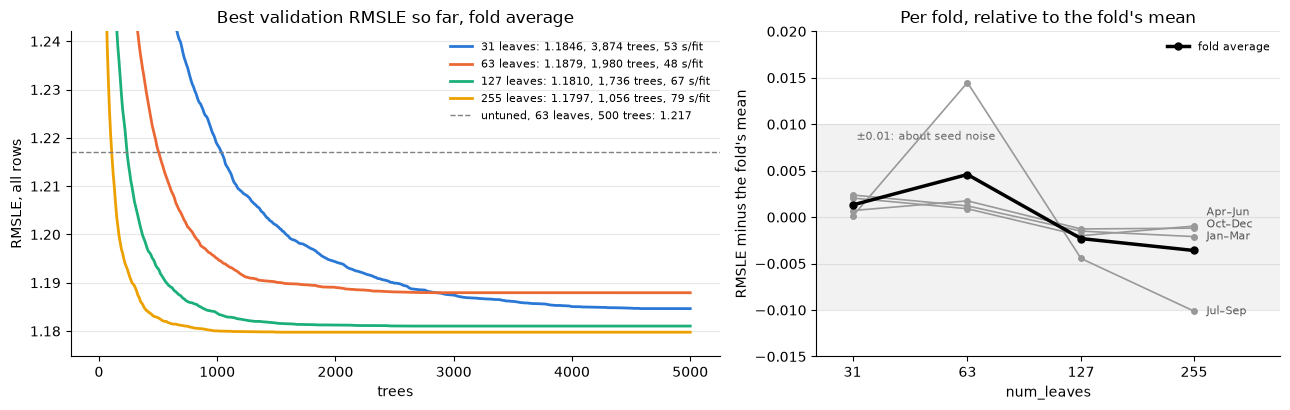

In [3]:
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT],
    filter_string=f"tags.stage = 'A' and tags.session = '{SESSION}'",
)
runs = runs.assign(leaves=runs["params.num_leaves"].astype(int))
leaves_run = sorted(runs.leaves.unique())
untuned = mlflow.search_runs(
    experiment_names=["ashrae-baseline-building"],
    filter_string="tags.model = 'lgbm_building'",
)
untuned_score = untuned[untuned["tags.session"] == untuned["tags.session"].max()][
    "metrics.val_rmsle"
].mean()


def best_so_far(run_id):
    """Lowest validation RMSLE reached by each tree count, held flat after the fold stopped."""
    history = sorted(
        client.get_metric_history(run_id, "val_rmsle_curve_all"), key=lambda m: m.step
    )
    curve = np.full(MAX_TREES // CURVE_EVERY, np.nan)
    curve[: len(history)] = np.minimum.accumulate([m.value for m in history])
    return pd.Series(curve).ffill().to_numpy()


trees_axis = np.arange(CURVE_EVERY, MAX_TREES + 1, CURVE_EVERY)
summary = runs.groupby("leaves").agg(
    trees=("metrics.trial_trees", "first"),
    rmsle=("metrics.val_rmsle", "mean"),
    seconds=("metrics.train_seconds", "mean"),
)
by_fold = runs.pivot(index="leaves", columns="tags.fold", values="metrics.val_rmsle")[
    FOLD_NAMES
]
relative = (
    by_fold - by_fold.mean()
)  # each fold against its own mean over the tree sizes

COLORS = dict(zip(leaves_run, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]}
)

ax = axes[0]
for leaves in leaves_run:
    curve = np.mean(
        [best_so_far(run_id) for run_id in runs[runs.leaves == leaves].run_id], axis=0
    )
    s = summary.loc[leaves]
    ax.plot(
        trees_axis,
        curve,
        color=COLORS[leaves],
        lw=2,
        label=f"{leaves} leaves: {s.rmsle:.4f}, {int(s.trees):,} trees, {s.seconds:.0f} s/fit",
    )
ax.axhline(
    untuned_score,
    color="gray",
    ls="--",
    lw=1,
    label=f"untuned, 63 leaves, 500 trees: {untuned_score:.3f}",
)
ax.set(
    title="Best validation RMSLE so far, fold average",
    xlabel="trees",
    ylabel="RMSLE, all rows",
    ylim=(summary.rmsle.min() - 0.005, max(untuned_score, summary.rmsle.max()) + 0.025),
)
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
ax.axhspan(-0.01, 0.01, color="#999999", alpha=0.12, lw=0)  # about seed noise
ax.text(
    leaves_run[0],
    0.0093,
    " ±0.01: about seed noise",
    fontsize=8,
    color="#666",
    va="top",
)
label_y = relative.iloc[-1].sort_values()
for i in range(1, len(label_y)):  # keep the fold labels at least 0.0013 apart
    label_y.iloc[i] = max(label_y.iloc[i], label_y.iloc[i - 1] + 0.0013)
for fold in FOLD_NAMES:
    ax.plot(leaves_run, relative[fold], color="#999999", lw=1.2, marker="o", ms=4)
    ax.text(
        leaves_run[-1] * 1.08,
        label_y[fold],
        fold,
        fontsize=8,
        color="#555",
        va="center",
    )
ax.plot(
    leaves_run,
    relative.mean(axis=1),
    color="black",
    lw=2.5,
    marker="o",
    ms=5,
    label="fold average",
)
ax.set_xscale("log", base=2)
ax.set_xlim(leaves_run[0] / 1.25, leaves_run[-1] * 1.7)
ax.set(
    xticks=leaves_run,
    xticklabels=leaves_run,
    xlabel="num_leaves",
    ylabel="RMSLE minus the fold's mean",
    title="Per fold, relative to the fold's mean",
    ylim=(-0.015, 0.02),
)
ax.minorticks_off()
ax.legend(frameon=False, fontsize=8, loc="upper right")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in runs.run_id:
        client.log_artifact(run_id, FIGURE)

display(
    by_fold.assign(average=by_fold.mean(axis=1)).round(4).rename_axis("RMSLE, all rows")
)